### Module 3 — Supervised Learning: Classification


### Module Outline:

**Tuesday — building a classifier**
1. Types of Machine Learning
2. The data: every shot at a World Cup
3. Supervised Learning -- Classification
4. One classifier in depth: **logistic regression**
5. The other classifiers
6. Is our model any good?

**Thursday — judging a classifier**

7. Evaluating classification: the confusion matrix, precision, recall, F1, ROC-AUC

8. When the thing you care about is rare: imbalanced data and what to do about it

In [15]:
# setup
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
plt.rcParams["figure.dpi"] = 110

---
### 1 · Machine Learning Categories

| | What the data gives you | The question | In this course |
|---|---|---|---|
| <span style="color:#a02020">**Supervised**</span> | features **and** the right answer (a label) | learn the mapping features → label | Modules 3, 4, 6, 7 |
| **Unsupervised** | features only — *no* labels | find structure: which things group together? | Module 5 |
| **Reinforcement** | no labels; only rewards from acting | learn a policy by trial and consequence | not covered |

<br></br>

<p align="center">
<img src="https://raw.githubusercontent.com/sparks5969/course-advanced-data-analysis/main/ML.webp" width="640">
</p>

Under <span style="color:#a02020">**supervised learning**</span>:

| Label is… | Example | Name | When |
|---|---|---|---|
| a **category** | goal / no goal · default / no default · fraud / legitimate | **classification** | **Module 3** |
| a **number** | house price, air-ticket price, mpg | **regression** | Module 4 |



---
### 2 · Live Demo: every shot at a World Cup

<p align="center">
<img src="https://raw.githubusercontent.com/sparks5969/course-advanced-data-analysis/main/messi.jpg" width="640">
</p>


 A dataset contains **every shot from the 2022 World Cup and Euro 2024**. data source: **StatsBomb**

| Column | Meaning |
|---|---|
| `goal` | **the label y**: did this shot go in? (1/0) |
| `distance` | yards from the centre of the goal |
| `angle` | degrees of goal mouth visible from the shot location — a wide-open view is a big angle |
| `body_part` | Right Foot · Left Foot · Head · Other |
| `play_type` | Open Play · Penalty · Free Kick · Corner |
| `under_pressure` | was a defender closing the shooter down? |
| `first_time` | struck without controlling the ball first |
| `statsbomb_xg` | prediction being made by professionals, using larger dataset and more features |
| `player`, `team`, `minute`, `x`, `y` | context |

The feature **xG — "expected goals" — is the probability that a shot becomes a goal**. It is derived from a model trained on hundreds of thousands of historical shots, using the shot's geometry, the body part, the type of play.

Think of it as a professional model's predictions. We will use that feature as a reference.

### Our prediction task:

> **A shot has just been struck. Before we see what happens: we will predict if it will end up in the net?**

- **The label (y):** `goal` — 1 if that shot went in, 0 if it did not
- **The features (X):** what we know *at the moment the ball is struck* — how far out, how much of the goal is visible, which body part, was a defender closing in, was it a penalty or open play
- **One row = one shot.** 2,834 shots in all.

In [29]:
shots = pd.read_csv("https://raw.githubusercontent.com/sparks5969/course-advanced-data-analysis/main/shots_statsbomb.csv")

print("shots:", len(shots), " | columns:", shots.shape[1])
print("goal rate:", f"{shots.goal.mean()*100:.1f}%")
shots.head(5)

shots: 2834  | columns: 14
goal rate: 11.3%


,competition,team,player,minute,x,y,distance,angle,body_part,play_type,under_pressure,first_time,goal,statsbomb_xg
0,World Cup 2022,Canada,Mark Anthony Kaye,2,96.5,40.7,23.51,19.30,Left Foot,Open Play,1,1,0,0.0389
1,World Cup 2022,Morocco,Hakim Ziyech,3,83.9,45.0,36.44,12.41,Left Foot,Open Play,0,1,1,0.0245
2,World Cup 2022,Morocco,Abdelhamid Sabiri,8,86.8,38.4,33.24,13.71,Right Foot,Free Kick,0,0,0,0.0221
3,World Cup 2022,Morocco,Sofiane Boufal,9,107.0,48.3,15.42,25.11,Left Foot,Open Play,0,0,0,0.0616
4,World Cup 2022,Canada,Tajon Buchanan,14,113.3,34.9,8.42,44.31,Right Foot,Open Play,0,1,0,0.2791


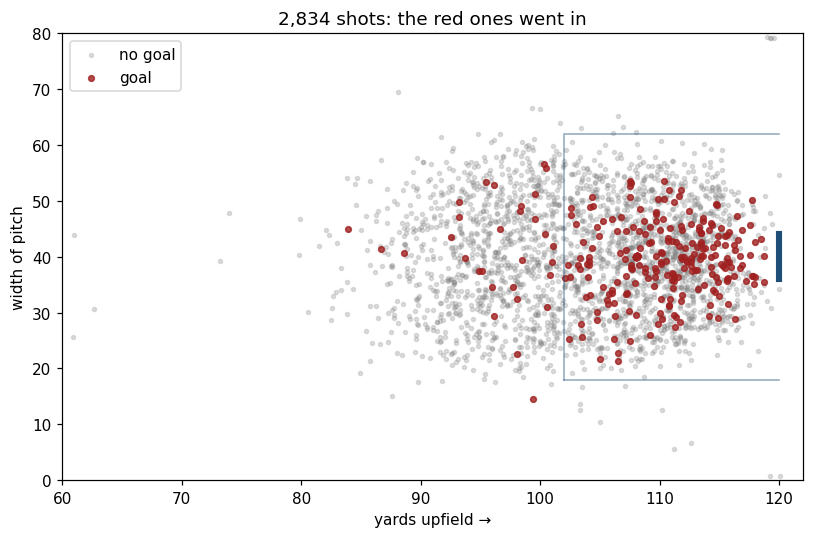

In [19]:
# where are shots taken from, and which go in?
goals = shots[shots.goal == 1]; misses = shots[shots.goal == 0]
plt.figure(figsize=(7.5, 5))
plt.scatter(misses.x, misses.y, s=7, alpha=0.25, color="gray", label="no goal")
plt.scatter(goals.x, goals.y, s=14, alpha=0.8, color="#a02020", label="goal")
plt.plot([120,120],[36,44], color="#1f4e79", lw=4)                     # the goal mouth
plt.plot([102,102,120],[18,62,62], color="#1f4e79", lw=1, alpha=.5)    # penalty area (sketch)
plt.plot([102,120],[18,18], color="#1f4e79", lw=1, alpha=.5)
plt.xlim(60, 122); plt.ylim(0, 80); plt.xlabel("yards upfield →"); plt.ylabel("width of pitch")
plt.title("2,834 shots: the red ones went in"); plt.legend(loc="upper left"); plt.tight_layout(); plt.show()

In [20]:
# the physics of football, in one table
bands = pd.cut(shots.distance, [0, 6, 12, 18, 25, 40, 100])
summary = shots.groupby(bands, observed=True).agg(
    shots=("goal", "size"),
    goal_rate=("goal", "mean"),
    pros_mean_xg=("statsbomb_xg", "mean")).round(3)
summary

,shots,goal_rate,pros_mean_xg
distance,,,
"(0, 6]",80,0.425,0.422
"(6, 12]",711,0.233,0.242
"(12, 18]",680,0.107,0.105
"(18, 25]",711,0.045,0.050
"(25, 40]",633,0.025,0.023
"(40, 100]",19,0.000,0.007


Two things worth pausing on:

- **Goal rate collapses with distance** — 42% from inside six yards, 2.5% from beyond 25. Distance is going to be a powerful feature.

- **Look down the last two columns.** In every band, the professionals' average prediction lands almost exactly on the actual goal rate (0.425 vs 0.422 · 0.107 vs 0.105 · 0.045 vs 0.050). That is what a **well-calibrated** model looks like: when it says 10%, roughly 10% go in. It is also our sanity check that the `distance` we computed means what we think it means.

---
### 3 · From numbers to categories

A classifier works in **three steps**:

### **probability &rarr; threshold &rarr; decision**

1. **The probability.** The model's real output is *how likely* the positive class is: P(goal) = 0.23, P(default) = 0.04. This is a continuous number between 0 and 1. In this particular example, **Every shot gets a probability** — a tap-in, a header, a penalty, a hopeful effort from 40 yards. Our model needs to make this probability close to reality.

2. **The threshold.** A rule you choose: where is the **cutoff**. This cutoff will convert your probability into categories, often 0 or 1.

3. **The decision.** What you actually do: flag the transaction, deny the loan, send the alert.

The **probability** is a statement about the world, while the threshold is a statement about *your priorities*. Two banks with the identical model will set different thresholds if one fears defaults more than lost business.

Let's look at eight real shots, with the probability a professional model assigned to each, and what three different thresholds would decide:

In [36]:
demo = shots.sort_values("statsbomb_xg").iloc[[5, 400, 900, 1400, 1900, 2300, 2700, 2833]].copy()
out = pd.DataFrame({
    "player": demo.player.str[:22],
    "distance": demo.distance.round(1),
    "P(goal)": demo.statsbomb_xg.round(3),
    "decision @ t=0.5": np.where(demo.statsbomb_xg >= 0.50, "GOAL", "—"),
    "decision @ t=0.3": np.where(demo.statsbomb_xg >= 0.30, "GOAL", "—"),
    "decision @ t=0.1": np.where(demo.statsbomb_xg >= 0.10, "GOAL", "—"),
    "actually?": np.where(demo.goal == 1, "GOAL", "no"),
})
out.reset_index(drop=True)

,player,distance,P(goal),decision @ t=0.5,decision @ t=0.3,decision @ t=0.1,actually?
0,Nicolae Claudiu Stanci,39.2,0.000,—,—,—,no
1,Aymeric Laporte,29.3,0.021,—,—,—,no
2,Dan Ndoye,20.3,0.035,—,—,—,no
3,Daniel Olmo Carvajal,20.5,0.053,—,—,—,no
4,Frederico Rodrigues Sa,12.4,0.084,—,—,—,no
5,Bruno Guimarães Rodrig,6.5,0.149,—,—,GOAL,no
6,Breel-Donald Embolo,8.1,0.552,GOAL,GOAL,GOAL,GOAL
7,Aleksandar Mitrović,6.4,0.898,GOAL,GOAL,GOAL,GOAL


Note that **the probabilities never changed** — only the threshold did, and the decisions moved with it. Lower the threshold and you catch more goals but cry wolf more often; raise it and the reverse.

---
### 4 · One classifier in depth: logistic regression

### First: let's run a linear regression?

Our label is 0 or 1. Nothing stops us from fitting OLS to it — so let's see what happens.

In [22]:
ols = LinearRegression().fit(shots[["distance"]], shots.goal)
for d in [5, 20, 35, 50, 70]:
    X_test = pd.DataFrame([[d]], columns=["distance"])
    print(f"distance {d:>2} yards → OLS says P(goal) = {ols.predict(X_test)[0]: .3f}")

print(" ")
print("A negative probability is not interpretable. we need something between 0 and 1")


distance  5 yards → OLS says P(goal) =  0.237
distance 20 yards → OLS says P(goal) =  0.099
distance 35 yards → OLS says P(goal) = -0.039
distance 50 yards → OLS says P(goal) = -0.177
distance 70 yards → OLS says P(goal) = -0.361
 
A negative probability is not interpretable. we need something between 0 and 1


### A common approach: squeeze the line through a sigmoid

Logistic regression keeps the familiar linear combination — β₀ + β₁·distance + β₂·angle — but passes it through the **logistic (sigmoid) function**:

$$P(\text{goal}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \beta_2 x_2 + \cdots)}}$$

Whatever the linear part computes — minus a million or plus a million — the sigmoid maps it into (0, 1):

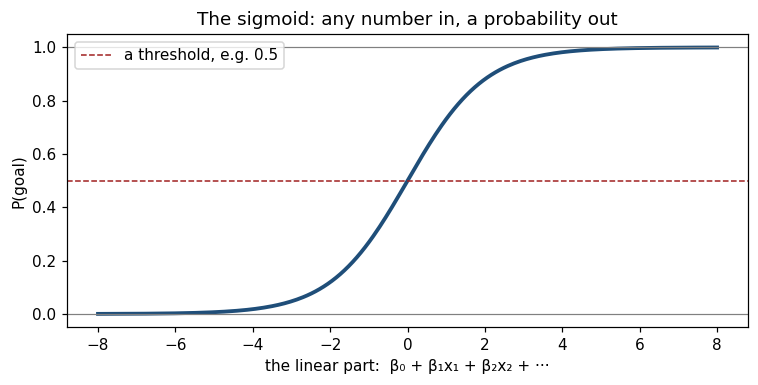

In [23]:
z = np.linspace(-8, 8, 300)
plt.figure(figsize=(7, 3.6))
plt.plot(z, 1/(1+np.exp(-z)), color="#1f4e79", lw=2.5)
plt.axhline(0, color="gray", lw=.8); plt.axhline(1, color="gray", lw=.8)
plt.axhline(0.5, color="#a02020", ls="--", lw=1, label="a threshold, e.g. 0.5")
plt.xlabel("the linear part:  β₀ + β₁x₁ + β₂x₂ + ···"); plt.ylabel("P(goal)")
plt.title("The sigmoid: any number in, a probability out"); plt.legend(); plt.tight_layout(); plt.show()

**A note for the econometricians in the room.** You probably already know this model — perhaps estimated logits to *interpret* coefficients. For example, to ask whether education raises the probability of employment. Here, the identical tool is pointed at a different goal: we do not care much what β₁ *is*, we care whether P̂ is *right on shots the model has never seen*. Same estimator, different question — this is the explain-vs-predict distinction we talked about.



### Model Training
(and mind the framework we learned)

In [37]:
train, test = train_test_split(shots, test_size=0.2, random_state=42, stratify=shots.goal)
FEATURES = ["distance", "angle"]

model = make_pipeline(StandardScaler(), LogisticRegression())   # scaler fit on TRAIN only
model.fit(train[FEATURES], train.goal)

test = test.copy()
test["our_p"] = model.predict_proba(test[FEATURES])[:, 1]       # column 1 = P(class 1)
print(f"trained on {len(train)} shots, predicting {len(test)} unseen shots\n")
print(test[["player","distance","angle","our_p","statsbomb_xg","goal"]].head(5).round(3).to_string(index=False))

trained on 2267 shots, predicting 567 unseen shots

              player  distance  angle  our_p  statsbomb_xg  goal
        Jae-Sung Lee     24.64  16.65  0.043         0.021     0
 Anzor Mekvabishvili     17.87  24.27  0.086         0.054     0
        Ivan Perišić     37.90  11.99  0.013         0.008     0
           Dan Ndoye     17.35  25.76  0.092         0.294     0
Danilo Luiz da Silva     27.97  14.12  0.031         0.017     0


`predict_proba` returns the probability — the model's actual output. (`predict` would hand us 0/1 decisions at a threshold of 0.5, silently making a choice that should be ours.)

### Does our two-feature model know anything?

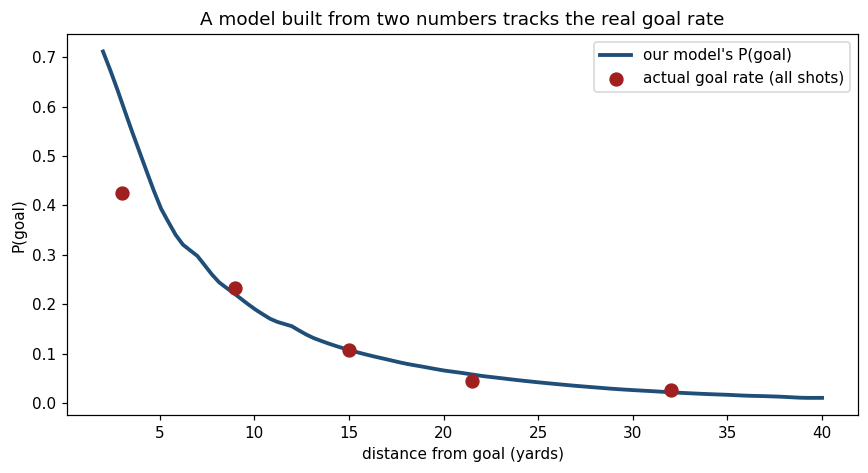

In [38]:
# our predicted curve against reality, by distance
grid = pd.DataFrame({"distance": np.linspace(2, 40, 100), "angle": np.nan})
grid["angle"] = np.interp(grid.distance, shots.groupby(shots.distance.round()).distance.mean(),
                          shots.groupby(shots.distance.round()).angle.mean())   # typical angle at each distance
grid["p"] = model.predict_proba(grid[FEATURES])[:, 1]

band_mid = [3, 9, 15, 21.5, 32]
band_rate = shots.groupby(pd.cut(shots.distance, [0,6,12,18,25,40]), observed=True).goal.mean().values

plt.figure(figsize=(8, 4.4))
plt.plot(grid.distance, grid.p, color="#1f4e79", lw=2.5, label="our model's P(goal)")
plt.scatter(band_mid, band_rate, color="#a02020", s=70, zorder=5, label="actual goal rate (all shots)")
plt.xlabel("distance from goal (yards)"); plt.ylabel("P(goal)")
plt.title("A model built from two numbers tracks the real goal rate")
plt.legend(); plt.tight_layout(); plt.show()

### Is our prediction close to the professional's work?

Our model has now assigned a probability to all 851 unseen shots. The professionals' model has done the same, on the same shots. Comparing the two columns is a free diagnostic — **not to see who wins, but to find out where our prediction and the professional prediction disagree the most**

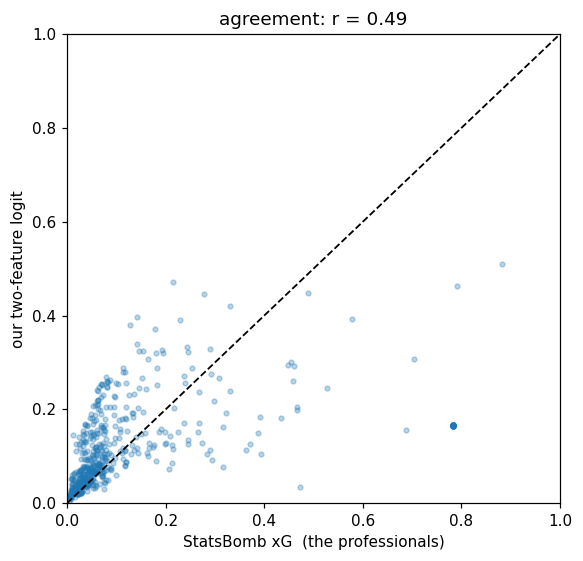

Where we disagree most — our model is far too pessimistic:
                        player  distance play_type  our_p  statsbomb_xg
               André Ayew Pelé      12.0   Penalty  0.164         0.784
Lionel Andrés Messi Cuccittini      12.0   Penalty  0.164         0.784
                  Mislav Oršić      12.0   Penalty  0.164         0.784
            Robert Lewandowski      12.0   Penalty  0.164         0.784


In [39]:
plt.figure(figsize=(5.4, 5.2))
plt.scatter(test.statsbomb_xg, test.our_p, s=10, alpha=.3)
plt.plot([0,1],[0,1], "k--", lw=1.2)
plt.xlabel("StatsBomb xG  (the professionals)"); plt.ylabel("our two-feature logit")
plt.title(f"agreement: r = {test.our_p.corr(test.statsbomb_xg):.2f}")
plt.xlim(0,1); plt.ylim(0,1); plt.tight_layout(); plt.show()

print("Where we disagree most — our model is far too pessimistic:")
test["gap"] = test.our_p - test.statsbomb_xg
print(test.nsmallest(4, "gap")[["player","distance","play_type","our_p","statsbomb_xg"]].round(3).to_string(index=False))

<span style="color:#a02020">**Every one of the worst disagreements is a penalty.**</span>

Here is what happened: Our model knows only two things about a shot: distance and angle. A penalty is taken from 12 yards, so the model files it with every other 12-yard shot and says *"about 16% — that is what shots from this distance do."*

But a penalty is not like other 12-yard shots. **There is no defender in the way, and the goalkeeper may not move until the ball is struck.** The professionals' model knows this; ours was never told. In reality, penalties are converted about 70–78% of the time.

So the model is not broken, and logistic regression is not the problem — <span style="color:#1f4e79">**a feature is missing.**</span> Let us hand it the one it needs:

In [27]:
RICH = ["distance", "angle", "under_pressure", "first_time"]
X_tr = pd.get_dummies(train[RICH + ["body_part", "play_type"]], drop_first=True)
X_te = pd.get_dummies(test[RICH + ["body_part", "play_type"]], drop_first=True).reindex(columns=X_tr.columns, fill_value=0)

rich = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_tr, train.goal)
test["rich_p"] = rich.predict_proba(X_te)[:, 1]

pens = test[test.play_type == "Penalty"]
print(f"PENALTIES (n={len(pens)}):")
print(f"   two-feature model : {pens.our_p.mean():.2f}")
print(f"   richer model      : {pens.rich_p.mean():.2f}")
print(f"   professionals     : {pens.statsbomb_xg.mean():.2f}")
print(f"   actually scored   : {pens.goal.mean():.2f}")
print(f"\nagreement with the pros — two features: r = {test.our_p.corr(test.statsbomb_xg):.2f}"
      f"   |   richer: r = {test.rich_p.corr(test.statsbomb_xg):.2f}")

PENALTIES (n=32):
   two-feature model : 0.17
   richer model      : 0.72
   professionals     : 0.78
   actually scored   : 0.69

agreement with the pros — two features: r = 0.55   |   richer: r = 0.92


One categorical variable, and the model stops insulting penalty takers.

**Principle: Better features beat better algorithms**

---
### 5 · Other classifiers (briefly)

Logistic regression is one way to turn features into a probability. There are many, and you will meet them soon:

| Classifier | The idea in one line | Where it appears |
|---|---|---|
| **k-nearest neighbours** | ask the *k* most similar shots what happened to them | Module 4 |
| **Decision tree** | ask a series of yes/no questions; each leaf holds a probability | Module 4 |
| **Random forest / boosting** | grow hundreds of trees and combine them | Module 4 |
| **Neural network** | stack simple units so the model can learn its own features | Module 7 |


> <span style="color:#1f4e79">**They all share one interface: features in, probability out.**</span>

Swap `LogisticRegression()` for `RandomForestClassifier()` and the rest of your code is untouched

---
### 6 · So… is our model any good?

Let's ask the obvious question the obvious way — what fraction of shots does it call correctly?

In [40]:
decisions = (test.our_p >= 0.5).astype(int)
accuracy = (decisions == test.goal).mean()
print(f"our model's accuracy:        {accuracy:.3f}")

lazy = np.zeros(len(test), dtype=int)       # a 'model' that says NO GOAL to every shot
print(f"'never a goal' accuracy:     {(lazy == test.goal).mean():.3f}")
print(f"\ngoals our model found: {int(((decisions==1) & (test.goal==1)).sum())} out of {int(test.goal.sum())}")

our model's accuracy:        0.889
'never a goal' accuracy:     0.887

goals our model found: 1 out of 64


<span style="color:#a02020; font-size:17px">**Our model scored 89%**</span>

- In other words, out of 100 guesses, our model get 89 of them correctly. Impressive?

- But wait a second...in the football world, getting a goal is very hard. A rule that refuses to predict any goal at all scores 88.7%.

- All of our modelling bought **0.2 percentage points** of improvement.

- And yet we have just watched this model track the real goal rate across distances, and — once given the right features — agree with a professional model at r = 0.92.

- Something is badly wrong, and it is not the model. It is <span style="color:#1f4e79">**the question we asked of it.**</span>

Accuracy counts *how often you are right*. It says nothing about *which mistakes you made*. When one class is rare, you can be right almost always by never looking for the rare thing — which is exactly what a 0.5 threshold did to us here.

Our shots are 11% goals, which is rare, but not exetremly rare. When we're looking at exteremly rare events, model accuracy does not merely mislead — it conceals a model that finds nothing at all.

**Thursday:** how to actually judge a classifier, and what to do when the thing you care about is rare.

--